
## HW2 : Uniform Convergence and the Limits of Learning

## Part I – Simulating Uniform Convergence

### 1. Empirical Risk as a Random Variable

For a hypothesis with true risk $p_j$, the number of errors on a training sample of size $m$ follows a binomial distribution:

$$
E_j \sim \mathrm{Binomial}(m,p_j)
$$

The empirical risk is calculated as $L_S(h_j)=E_j/m$. We will study how its distribution changes as the sample size increases.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#Parameters
p = 0.2 #true error
sample_sizes = [10, 50, 100] #m
n_repetitions = 1000

In [ ]:

for m in sample_sizes:
    #We are considering a binominial distribution to simulate the number of errors
    #m number of examples, p probability of error and n number of repetitons
    errors = np.random.binomial(m, p, n_repetitions)

    #Calculate the empirical risk for every repetition
    empirical_risks = errors / m

    print("Sample size:", m)
    print("Mean empirical risk:", np.mean(empirical_risks))
    print()


Sample size: 10
Mean empirical risk: 0.1995

Sample size: 50
Mean empirical risk: 0.20026000000000005

Sample size: 100
Mean empirical risk: 0.19951



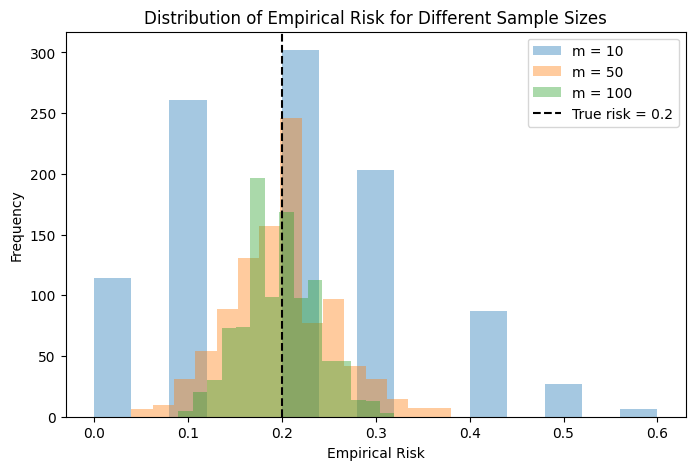

In [6]:
#Visualization
plt.figure(figsize=(8, 5))

for m in sample_sizes:
    errors = np.random.binomial(m, p, n_repetitions)
    empirical_risks = errors / m

    plt.hist(
        empirical_risks,
        bins=15,
        alpha=0.4,
        label=f"m = {m}"
    )

plt.axvline(p, linestyle="--", color="black", label="True risk = 0.2")
plt.xlabel("Empirical Risk")
plt.ylabel("Frequency")
plt.title("Distribution of Empirical Risk for Different Sample Sizes")
plt.legend()
plt.show()


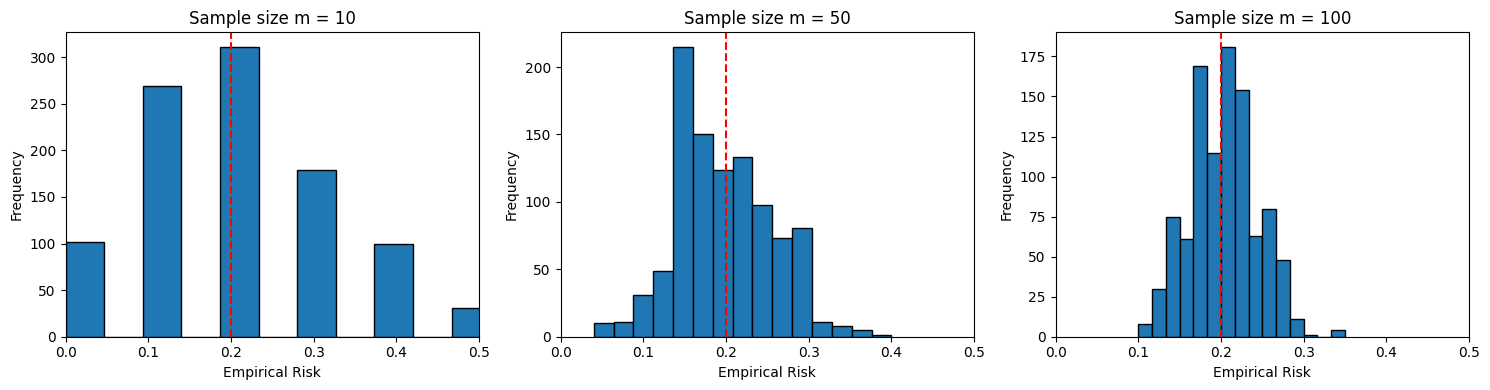

In [8]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, m in zip(axes, sample_sizes):
    errors = np.random.binomial(m, p, n_repetitions)
    empirical_risks = errors / m

    ax.hist(empirical_risks, bins=15, edgecolor="black")
    ax.axvline(p, linestyle="--", color="red")
    ax.set_xlim(0, 0.5)
    ax.set_title(f"Sample size m = {m}")
    ax.set_xlabel("Empirical Risk")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


The mean empirical risk is expected to be close to the true risk of 0.2. As the sample size increases, the empirical risk becomes less variable and more concentrated around the true risk. This illustrates how larger samples provide more reliable estimates of the true risk.

### Deviation Between Empirical and True Risk

In [10]:
epsilon = 0.1
n_repetitions = 1000

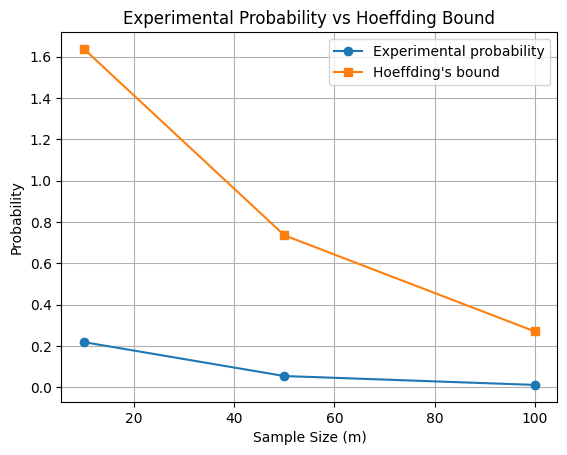

In [13]:
#Estimating the probability that the empirical risk deviates from the true risk by more than epsilon
#Comparing the estimated probability with the Hoeffding bound
experimental_probabilities = []
hoeffding_bounds = []

for m in sample_sizes:
    errors = np.random.binomial(m, p, n_repetitions)
    empirical_risks = errors / m
    deviations = np.abs(empirical_risks - p)

    estimated_probability = np.mean(deviations > epsilon)
    hoeffding_bound = 2 * np.exp(-2 * m * epsilon**2)

    experimental_probabilities.append(estimated_probability)
    hoeffding_bounds.append(hoeffding_bound)

plt.plot(sample_sizes, experimental_probabilities, marker='o', label='Experimental probability')
plt.plot(sample_sizes, hoeffding_bounds, marker='s', label="Hoeffding's bound")
plt.xlabel('Sample Size (m)')
plt.ylabel('Probability')
plt.title('Experimental Probability vs Hoeffding Bound')
plt.legend()
plt.grid(True)
plt.show()


The estimated probability of a deviation greater than $\epsilon = 0.1$ decreases as the sample size increases. This is because the empirical risk becomes more concentrated around the true risk when more training examples are available. The results illustrate that larger samples provide more reliable estimates of the true risk.

The Hoeffding bound is generally greater than the experimentally estimated probability. This shows that the bound is conservative rather than exact. It provides a theoretical upper limit on the probability of a large deviation, but it may overestimate the actual probability.

### From One Hypothesis to Uniform Convergence

In [ ]:
#Get the maximum deviation for a sample size m 
m = 50
K = 10
true_risks = np.linspace(0.1, 0.5, K)

#Simulate the number of errors for each hypothesis
errors = np.random.binomial(m, true_risks)

#Calculate empirical risks
empirical_risks = errors / m

#Calculate absolute deviations
deviations = np.abs(empirical_risks - true_risks)

#Keep the hypothesis with the largest deviation
delta_S = np.max(deviations)

print("True risks:", true_risks)
print("Empirical risks:", empirical_risks)
print("Deviations:", deviations)
print("Maximum deviation:", delta_S)


True risks: [0.1        0.14444444 0.18888889 0.23333333 0.27777778 0.32222222
 0.36666667 0.41111111 0.45555556 0.5       ]
Empirical risks: [0.04 0.18 0.14 0.14 0.22 0.24 0.54 0.28 0.48 0.44]
Deviations: [0.06       0.03555556 0.04888889 0.09333333 0.05777778 0.08222222
 0.17333333 0.13111111 0.02444444 0.06      ]
Maximum deviation: 0.17333333333333334


In [22]:
#Do it for diffrent sample sizes 
epsilon = 0.1
n_repetitions = 1000
K = 10
true_risks = np.linspace(0.1, 0.5, K)

uniform_probabilities = []

#For each m we will repeat the experiment n times and increase the failures counter if 
#the maximum deviation exceeds epsilon
for m in sample_sizes:
    failure_count = 0

    for _ in range(n_repetitions):
        errors = np.random.binomial(m, true_risks)
        empirical_risks = errors / m

        deviations = np.abs(empirical_risks - true_risks)
        delta_S = np.max(deviations)

        if delta_S > epsilon:
            failure_count += 1

    #Probability of having a maximum deviation greater than epsilon
    probability = failure_count / n_repetitions
    uniform_probabilities.append(probability)

    print("Sample size:", m)
    print("Estimated probability:", probability)
    print()


Sample size: 10
Estimated probability: 0.996

Sample size: 50
Estimated probability: 0.672

Sample size: 100
Estimated probability: 0.208



In [23]:
#Comparison with the hoeffding bound
uniform_hoeffding_bounds = []

for m in sample_sizes:
    bound = 2 * K * np.exp(-2 * m * epsilon**2)
    uniform_hoeffding_bounds.append(bound)

print("Experimental probabilities:", uniform_probabilities)
print("Theoretical bounds:", uniform_hoeffding_bounds)

Experimental probabilities: [0.996, 0.672, 0.208]
Theoretical bounds: [np.float64(16.374615061559638), np.float64(7.357588823428845), np.float64(2.7067056647322523)]


Experimental probability decreases as \(m\) increases, from 0.999 to 0.221.
Theoretical bound also decreases, but remains above 1 for all three sample sizes.
The bound is conservative it guarantees an upper limit mathematically, but that limit may be much larger than the observed probability.

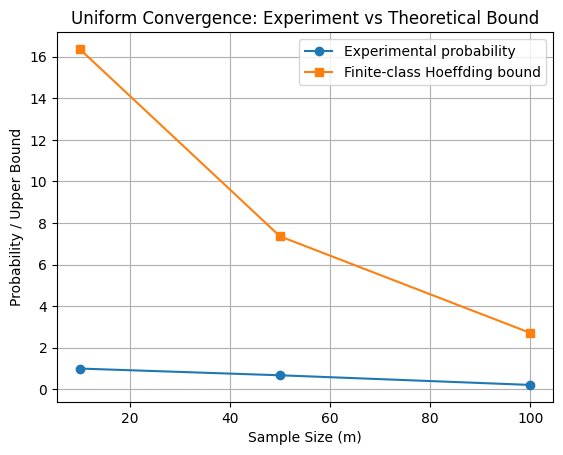

In [ ]:
#Visualization for mutiple hypotheses
plt.plot(sample_sizes, uniform_probabilities, marker='o',label='Experimental probability')
plt.plot(sample_sizes, uniform_hoeffding_bounds, marker='s',label="Finite-class Hoeffding bound")

plt.xlabel('Sample Size (m)')
plt.ylabel('Probability / Upper Bound')
plt.title('Uniform Convergence: Experiment vs Theoretical Bound')
plt.legend()
plt.grid(True)
plt.show()

The experimental probability of failure decreases as the sample size increases. Since uniform convergence considers all hypotheses simultaneously, the probability of failure can be higher than when considering a single hypothesis. The finite-class Hoeffding bound also decreases with the sample size, but it is conservative and exceeds 1 for the sample sizes considered.

### Effect of the Size of the Hypothesis Class

In [25]:
class_sizes = [5, 10, 50, 100, 500]

sample_sizes = [10, 50, 100]
epsilon = 0.1
n_repetitions = 1000

In [ ]:
#True risks for the classes 
for K in class_sizes:
    true_risks = np.linspace(0.1, 0.5, K)

Class size: 5
Number of true risks: 5
Class size: 10
Number of true risks: 10
Class size: 50
Number of true risks: 50
Class size: 100
Number of true risks: 100
Class size: 500
Number of true risks: 500


In [ ]:
#Same logic but diffrent class sizes 
results = {}

for K in class_sizes:
    true_risks = np.linspace(0.1, 0.5, K)

    for m in sample_sizes:
        failure_count = 0

        for _ in range(n_repetitions):
            errors = np.random.binomial(m, true_risks)
            empirical_risks = errors / m

            deviations = np.abs(empirical_risks - true_risks)
            delta_S = np.max(deviations)

            if delta_S > epsilon:
                failure_count += 1

        probability = failure_count / n_repetitions
        results[(K, m)] = probability

        print("Class size:", K,
              "| Sample size:", m,
              "| Failure probability:", probability)

Class size: 5 | Sample size: 10 | Failure probability: 0.902
Class size: 5 | Sample size: 50 | Failure probability: 0.371
Class size: 5 | Sample size: 100 | Failure probability: 0.109
Class size: 10 | Sample size: 10 | Failure probability: 0.998
Class size: 10 | Sample size: 50 | Failure probability: 0.669
Class size: 10 | Sample size: 100 | Failure probability: 0.218
Class size: 50 | Sample size: 10 | Failure probability: 1.0
Class size: 50 | Sample size: 50 | Failure probability: 1.0
Class size: 50 | Sample size: 100 | Failure probability: 0.74
Class size: 100 | Sample size: 10 | Failure probability: 1.0
Class size: 100 | Sample size: 50 | Failure probability: 1.0
Class size: 100 | Sample size: 100 | Failure probability: 0.926
Class size: 500 | Sample size: 10 | Failure probability: 1.0
Class size: 500 | Sample size: 50 | Failure probability: 1.0
Class size: 500 | Sample size: 100 | Failure probability: 1.0


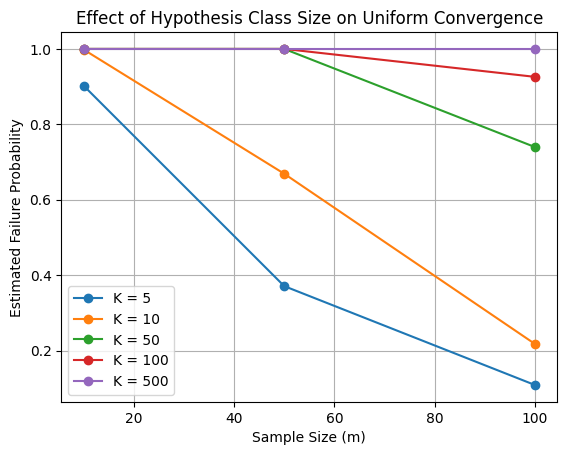

In [28]:
#Visualization
for K in class_sizes:
    probabilities = [results[(K, m)] for m in sample_sizes]

    plt.plot(sample_sizes, probabilities, marker='o',
             label=f'K = {K}')

plt.xlabel('Sample Size (m)')
plt.ylabel('Estimated Failure Probability')
plt.title('Effect of Hypothesis Class Size on Uniform Convergence')
plt.legend()
plt.grid(True)
plt.show()

The experimental results show that the probability of failure generally increases with the size of the hypothesis class. This is because uniform convergence requires all hypotheses to have empirical risks close to their true risks. As the class becomes larger, it becomes more likely that at least one hypothesis has a deviation greater than ε. Increasing the sample size reduces the probability of failure. This illustrates the trade-off between the size of the hypothesis class and the number of training examples needed for uniform convergence.

### Experimental Sample Complexity

In [29]:
#Application of the uniform convergence formula
K = 10
epsilon = 0.1
delta = 0.05

m_theoretical = np.log(2 * K / delta) / (2 * epsilon**2)

print("Theoretical sample size:", m_theoretical)
print("Sufficient integer sample size:", int(np.ceil(m_theoretical)))

Theoretical sample size: 299.573227355399
Sufficient integer sample size: 300


In [31]:
#Findying the experimental sample size  
candidate_sizes = [100, 150, 200, 250, 300, 350, 400]
K = 10
epsilon = 0.1
n_repetitions = 1000

experimental_sample_sizes = []

for m in candidate_sizes:
    true_risks = np.linspace(0.1, 0.5, K)
    failure_count = 0

    for _ in range(n_repetitions):
        errors = np.random.binomial(m, true_risks)
        empirical_risks = errors / m
        deviations = np.abs(empirical_risks - true_risks)
        delta_S = np.max(deviations)

        if delta_S > epsilon:
            failure_count += 1

    probability = failure_count / n_repetitions
    experimental_sample_sizes.append(probability)

    print("Sample size:", m,
          "| Failure probability:", probability)

Sample size: 100 | Failure probability: 0.244
Sample size: 150 | Failure probability: 0.073
Sample size: 200 | Failure probability: 0.019
Sample size: 250 | Failure probability: 0.009
Sample size: 300 | Failure probability: 0.003
Sample size: 350 | Failure probability: 0.001
Sample size: 400 | Failure probability: 0.0


For ε = 0.1, δ = 0.05, and a hypothesis class of size K = 10, the theoretical bound gives a sufficient sample size of approximately 300. Experimentally, the smallest tested sample size satisfying the target failure probability of 5% is 200. The experimental sample size is smaller because the theoretical Hoeffding bound is conservative. The experimental result is an estimate, whereas the theoretical bound provides a guarantee.

## Part II – Simulating No-Free-Lunch


### Seen and Unseen Inputs

In [33]:
N = 20
m = 10
n_repetitions = 1000

In [ ]:
#Observation of one experiment to understand
# Generate a random target function
target = np.random.binomial(1, 0.5, size=N)

#Draw m inputs uniformly from the domain {0, ..., N-1}
sample_inputs = np.random.randint(0, N, size=m)

#Find the distinct inputs that appeared
seen_inputs = np.unique(sample_inputs)

#Calculate the fraction of inputs never observed
fraction_unseen = 1 - len(seen_inputs) / N

print("Target function:", target)
print("Sample inputs:", sample_inputs)
print("Number of distinct inputs seen:", len(seen_inputs))
print("Fraction of unseen inputs:", fraction_unseen)

Target function: [0 0 0 0 0 0 1 1 0 0 0 0 1 1 0 1 0 0 1 1]
Sample inputs: [ 0 19 10 13 15 19  4 19  0 17]
Number of distinct inputs seen: 7
Fraction of unseen inputs: 0.65


In [35]:
#Repeat the experiment mutiple times 
experimental_fractions = []

for _ in range(n_repetitions):
    sample_inputs = np.random.randint(0, N, size=m)
    seen_inputs = np.unique(sample_inputs)

    fraction_unseen = 1 - len(seen_inputs) / N
    experimental_fractions.append(fraction_unseen)

experimental_mean = np.mean(experimental_fractions)
theoretical_fraction = (1 - 1 / N)**m

print("Experimental average:", experimental_mean)
print("Theoretical fraction:", theoretical_fraction)

Experimental average: 0.60115
Theoretical fraction: 0.5987369392383787


The experimental average fraction of unseen inputs (0.60115) is close to the theoretical value (0.59874). Small differences are expected due to randomness in the simulation. As the training sample may contain repeated inputs, some points in the domain remain unseen. The theoretical formula gives the probability that a fixed input is never sampled, which is also the expected fraction of unseen inputs because all inputs are equally likely to be sampled.

### Error on Unseen Inputs

In [ ]:
experimental_risks = []

for _ in range(n_repetitions):
    #Generate a new random target function
    target = np.random.binomial(1, 0.5, size=N)

    #Generate the training inputs
    sample_inputs = np.random.randint(0, N, size=m)

    #Memorize the observed labels
    predictions = np.zeros(N, dtype=int)

    for x in np.unique(sample_inputs):
        predictions[x] = target[x]

    #Calculate true risk over the whole domain
    true_risk = np.mean(predictions != target)
    experimental_risks.append(true_risk)

experimental_mean_risk = np.mean(experimental_risks)
theoretical_mean_risk = 0.5 * (1 - 1/N)**m

print("Experimental mean risk:", experimental_mean_risk)
print("Theoretical mean risk:", theoretical_mean_risk)

Experimental mean risk: 0.2981
Theoretical mean risk: 0.29936846961918934


The experimental mean true risk (0.2981) is close to the theoretical value (0.29937). The learner correctly predicts the labels of observed inputs by memorizing them. However, for unseen inputs, it always predicts 0, while the true labels are randomly generated with equal probability of being 0 or 1. Therefore, the expected error on unseen inputs is 0.5, and the overall expected risk is half the expected fraction of unseen inputs.

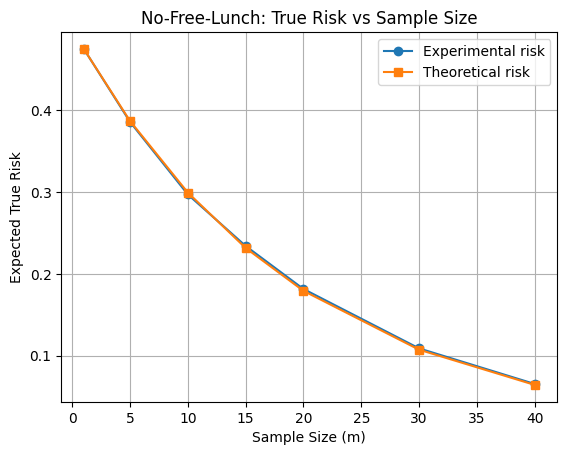

In [38]:
#Visualization
sample_sizes_nfl = [1, 5, 10, 15, 20, 30, 40]
n_repetitions = 1000

experimental_risks_by_m = []
theoretical_risks_by_m = []

for m in sample_sizes_nfl:
    risks = []

    for _ in range(n_repetitions):
        target = np.random.binomial(1, 0.5, size=N)
        sample_inputs = np.random.randint(0, N, size=m)

        predictions = np.zeros(N, dtype=int)

        for x in np.unique(sample_inputs):
            predictions[x] = target[x]

        risks.append(np.mean(predictions != target))

    experimental_risks_by_m.append(np.mean(risks))
    theoretical_risks_by_m.append(0.5 * (1 - 1/N)**m)

plt.plot(sample_sizes_nfl, experimental_risks_by_m, marker='o', label='Experimental risk')

plt.plot(sample_sizes_nfl, theoretical_risks_by_m, marker='s', label='Theoretical risk')

plt.xlabel('Sample Size (m)')
plt.ylabel('Expected True Risk')
plt.title('No-Free-Lunch: True Risk vs Sample Size')
plt.legend()
plt.grid(True)
plt.show()

### Changing predictions on unseen inputs

In [39]:
N = 20
m = 10
n_repetitions = 1000

risks_zero = []
risks_one = []
risks_random = []

for _ in range(n_repetitions):
    target = np.random.binomial(1, 0.5, size=N)
    sample_inputs = np.random.randint(0, N, size=m)
    seen_inputs = np.unique(sample_inputs)

    #Strategy 1: Always predict 0 for unseen inputs
    predictions_zero = np.zeros(N, dtype=int)

    #Strategy 2: Always predict 1 for unseen inputs
    predictions_one = np.ones(N, dtype=int)

    #Strategy 3: Random predictions for unseen inputs
    predictions_random = np.random.binomial(1, 0.5, size=N)

    #All strategies memorize observed labels
    for x in seen_inputs:
        predictions_zero[x] = target[x]
        predictions_one[x] = target[x]
        predictions_random[x] = target[x]

    risks_zero.append(np.mean(predictions_zero != target))
    risks_one.append(np.mean(predictions_one != target))
    risks_random.append(np.mean(predictions_random != target))

print("Always predict 0:", np.mean(risks_zero))
print("Always predict 1:", np.mean(risks_one))
print("Random prediction:", np.mean(risks_random))

Always predict 0: 0.29745000000000005
Always predict 1: 0.30060000000000003
Random prediction: 0.2992


The experimental results show that all three strategies have approximately the same average true risk: 0.297 for always predicting 0, 0.301 for always predicting 1, and 0.299 for random predictions. Small differences are due to randomness in the simulation. Since the target labels are generated randomly with equal probability of being 0 or 1, any prediction on an unseen input has an expected error of 0.5. Therefore, all three strategies have the same expected true risk, even though their predictions differ.
Changing the predictions on unseen inputs does not improve generalization when the target labels are completely random.